In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from google.colab import drive

drive.mount("/content/drive")

carpeta = Path("/content/drive/MyDrive/TP IA y Neuro/resultados")

archivos = [
    "resumen_test_clasico.csv",
    "resumen_test_llm.csv",
    "resumen_test_beto.csv"
]

resultados = pd.concat(
    [pd.read_csv(carpeta / archivo) for archivo in archivos],
    ignore_index=True
)

resultados = resultados.sort_values(
    "Macro-F1 Test", ascending=False
)

display(resultados)

Mounted at /content/drive


,Modelo,Macro-F1 Test,Inferencia Test (s),N Test,Respuestas inválidas
2,BETO fine-tuning (lr=2e-5),0.571458,1.222956,427,NaN
0,TF-IDF + Bigramas,0.535047,0.072998,427,NaN
1,Qwen2.5-1.5B Prompt mejorado,0.409010,38.195842,427,0.0


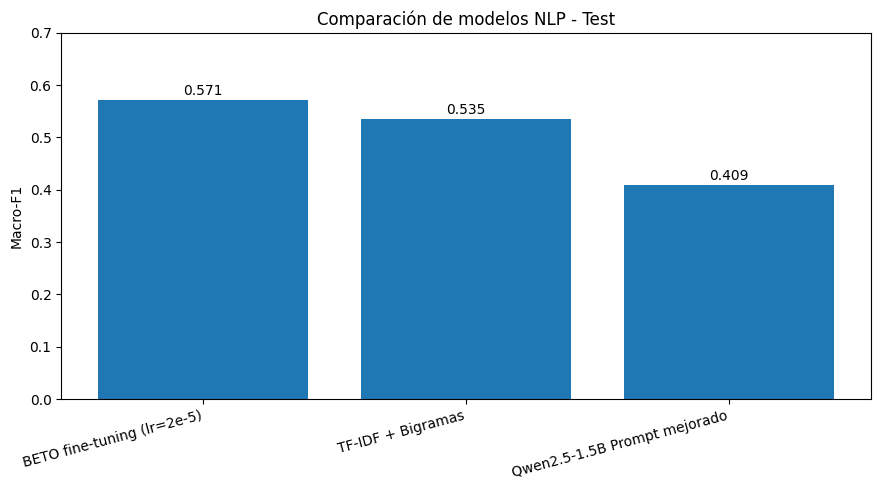

In [2]:
plt.figure(figsize=(9, 5))

bars = plt.bar(
    resultados["Modelo"],
    resultados["Macro-F1 Test"]
)

plt.ylabel("Macro-F1")
plt.title("Comparación de modelos NLP - Test")
plt.ylim(0, 0.7)
plt.xticks(rotation=15, ha="right")

for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height() + 0.01,
        f"{bar.get_height():.3f}",
        ha="center"
    )

plt.tight_layout()

plt.savefig(
    carpeta / "comparacion_modelos.png",
    dpi=200
)

plt.show()

In [3]:
resultados.to_csv(
    carpeta / "comparacion_final.csv",
    index=False
)

print("Comparación final guardada correctamente.")

Comparación final guardada correctamente.
